# BÀI TẬP 5.5 - GOM CỤM BÀI HÁT (MUSIC CLUSTERING) VỚI FMA DATASET
## SO SÁNH ĐỐI CHIẾU THUẬT TOÁN: DBSCAN VÀ K-MEANS
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)
**Mục tiêu bài toán:**
1. **Tiền xử lý:** Lọc tập `fma_small` (8.000 bài hát, 8 thể loại cân bằng), chuẩn hóa Z-score (`StandardScaler`) và giảm chiều PCA ($n=84$ thành phần giữ lại $\ge 80\%$ phương sai).
2. **Huấn luyện mô hình:**
   * **DBSCAN:** Thuật toán gom cụm dựa trên mật độ ($eps=15.0, min\_samples=5$).
   * **K-Means:** Thuật toán gom cụm dựa trên tâm cụm với $k=8$ (tương ứng 8 thể loại gốc).
3. **Đánh giá & So sánh:** Đối chiếu trực tiếp chất lượng phân cụm thông qua các chỉ số định lượng (Silhouette, Purity, ARI, NMI) và biểu đồ trực quan hóa 2D.

### 1. Import các thư viện cần thiết

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import (
    silhouette_score, 
    davies_bouldin_score, 
    calinski_harabasz_score,
    adjusted_rand_score, 
    normalized_mutual_info_score
)

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)

### 2. Nạp dữ liệu FMA (fma_small) & Giảm chiều PCA ($n=84$)

In [2]:
# 1. Đọc dữ liệu từ fma_metadata
data_dir = "fma_metadata/fma_metadata" if os.path.exists("fma_metadata/fma_metadata") else "fma_metadata"
tracks = pd.read_csv(os.path.join(data_dir, "tracks.csv"), index_col=0, header=[0, 1])
features = pd.read_csv(os.path.join(data_dir, "features.csv"), index_col=0, header=[0, 1, 2])

# 2. Lọc tập con fma_small (8,000 bài hát, 8 thể loại cân bằng)
small_mask = tracks[("set", "subset")] == "small"
tracks_small = tracks[small_mask].copy()
common_ids = tracks_small.index.intersection(features.index)

X = features.loc[common_ids].replace([np.inf, -np.inf], np.nan).fillna(0)
y_genre = tracks_small.loc[common_ids, ("track", "genre_top")]

# 3. Chuẩn hóa Z-score & Giảm chiều PCA
X_scaled = StandardScaler().fit_transform(X)
n_pca = 84
pca = PCA(n_components=n_pca, random_state=42)
X_pca = pca.fit_transform(X_scaled)

explained_var = np.sum(pca.explained_variance_ratio_) * 100
print(f"- Số lượng bài hát : {X.shape[0]:,} (8 thể loại cân bằng, mỗi thể loại 1,000 bài)")
print(f"- Số đặc trưng gốc : {X.shape[1]}")
print(f"- PCA {n_pca} thành phần giữ lại {explained_var:.2f}% tổng phương sai thông tin.")

- Số lượng bài hát : 8,000 (8 thể loại cân bằng, mỗi thể loại 1,000 bài)
- Số đặc trưng gốc : 518
- PCA 84 thành phần giữ lại 80.50% tổng phương sai thông tin.


### 3. Huấn luyện 2 Mô hình Gom cụm: DBSCAN và K-Means

In [3]:
# 1. Huấn luyện mô hình DBSCAN (eps=15.0, min_samples=5)
dbscan = DBSCAN(eps=15.0, min_samples=5, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X_pca)

db_n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
db_n_noise = np.sum(dbscan_labels == -1)
db_noise_pct = db_n_noise / len(dbscan_labels) * 100

# 2. Huấn luyện mô hình K-Means (k=8 tương ứng 8 thể loại gốc)
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

print("Huấn luyện hoàn tất cả 2 mô hình:")
print(f"• DBSCAN : {db_n_clusters} cụm phát hiện, {db_n_noise:,} bài ngoại lai / Noise ({db_noise_pct:.2f}%)")
print(f"• K-Means: 8 cụm phân chia bao phủ 100% dữ liệu (0 bài ngoại lai)")

Huấn luyện hoàn tất cả 2 mô hình:
• DBSCAN : 5 cụm phát hiện, 2,324 bài ngoại lai / Noise (29.05%)
• K-Means: 8 cụm phân chia bao phủ 100% dữ liệu (0 bài ngoại lai)


### 4. Bảng Đánh giá & So sánh Đối chiếu Toàn diện

In [4]:
def calculate_purity(y_true, y_pred):
    contingency_matrix = pd.crosstab(y_pred, y_true)
    return np.sum(np.amax(contingency_matrix.values, axis=1)) / np.sum(contingency_matrix.values)

# Đánh giá DBSCAN
db_mask = dbscan_labels != -1
db_sil = round(silhouette_score(X_pca[db_mask], dbscan_labels[db_mask], sample_size=min(3000, np.sum(db_mask)), random_state=42), 4)
db_db = round(davies_bouldin_score(X_pca[db_mask], dbscan_labels[db_mask]), 4)
db_ch = round(calinski_harabasz_score(X_pca[db_mask], dbscan_labels[db_mask]), 2)
db_purity = round(calculate_purity(y_genre, dbscan_labels), 4)
db_ari = round(adjusted_rand_score(y_genre, dbscan_labels), 4)
db_nmi = round(normalized_mutual_info_score(y_genre, dbscan_labels), 4)

# Đánh giá K-Means
km_sil = round(silhouette_score(X_pca, kmeans_labels, sample_size=3000, random_state=42), 4)
km_db = round(davies_bouldin_score(X_pca, kmeans_labels), 4)
km_ch = round(calinski_harabasz_score(X_pca, kmeans_labels), 2)
km_purity = round(calculate_purity(y_genre, kmeans_labels), 4)
km_ari = round(adjusted_rand_score(y_genre, kmeans_labels), 4)
km_nmi = round(normalized_mutual_info_score(y_genre, kmeans_labels), 4)

# Bảng so sánh tổng hợp
df_compare = pd.DataFrame({
    "Tiêu chí Đánh Giá": [
        "Trường phái Thuật toán",
        "Số Cụm (Clusters)",
        "Tỷ lệ Nhiễu (Noise %)",
        "Silhouette Score (Độ phân tách)",
        "Davies-Bouldin Index (Độ tương đồng)",
        "Calinski-Harabasz Index",
        "Cluster Purity (Độ thuần nhất)",
        "Adjusted Rand Index (ARI)",
        "Normalized Mutual Info (NMI)"
    ],
    "DBSCAN (eps=15.0)": [
        "Dựa trên Mật độ (Density-based)",
        db_n_clusters,
        f"{db_n_noise:,} ({db_noise_pct:.2f}%)",
        db_sil,
        db_db,
        db_ch,
        db_purity,
        db_ari,
        db_nmi
    ],
    "K-Means (k=8)": [
        "Dựa trên Tâm cụm (Centroid-based)",
        8,
        "0% (Phân cụm 100% dữ liệu)",
        km_sil,
        km_db,
        km_ch,
        km_purity,
        km_ari,
        km_nmi
    ]
})

df_compare

,Tiêu chí Đánh Giá,DBSCAN (eps=15.0),K-Means (k=8)
0,Trường phái Thuật toán,Dựa trên Mật độ (Density-based),Dựa trên Tâm cụm (Centroid-based)
1,Số Cụm (Clusters),5,8
2,Tỷ lệ Nhiễu (Noise %),"2,324 (29.05%)",0% (Phân cụm 100% dữ liệu)
3,Silhouette Score (Độ phân tách),0.1172,0.0295
4,Davies-Bouldin Index (Độ tương đồng),0.9431,2.8823
5,Calinski-Harabasz Index,32.33,320.14
6,Cluster Purity (Độ thuần nhất),0.1782,0.2956
7,Adjusted Rand Index (ARI),0.018,0.0876
8,Normalized Mutual Info (NMI),0.042,0.1426


### 5. Trực quan hóa So sánh Không gian Gom Cụm 2D (PCA Projection)

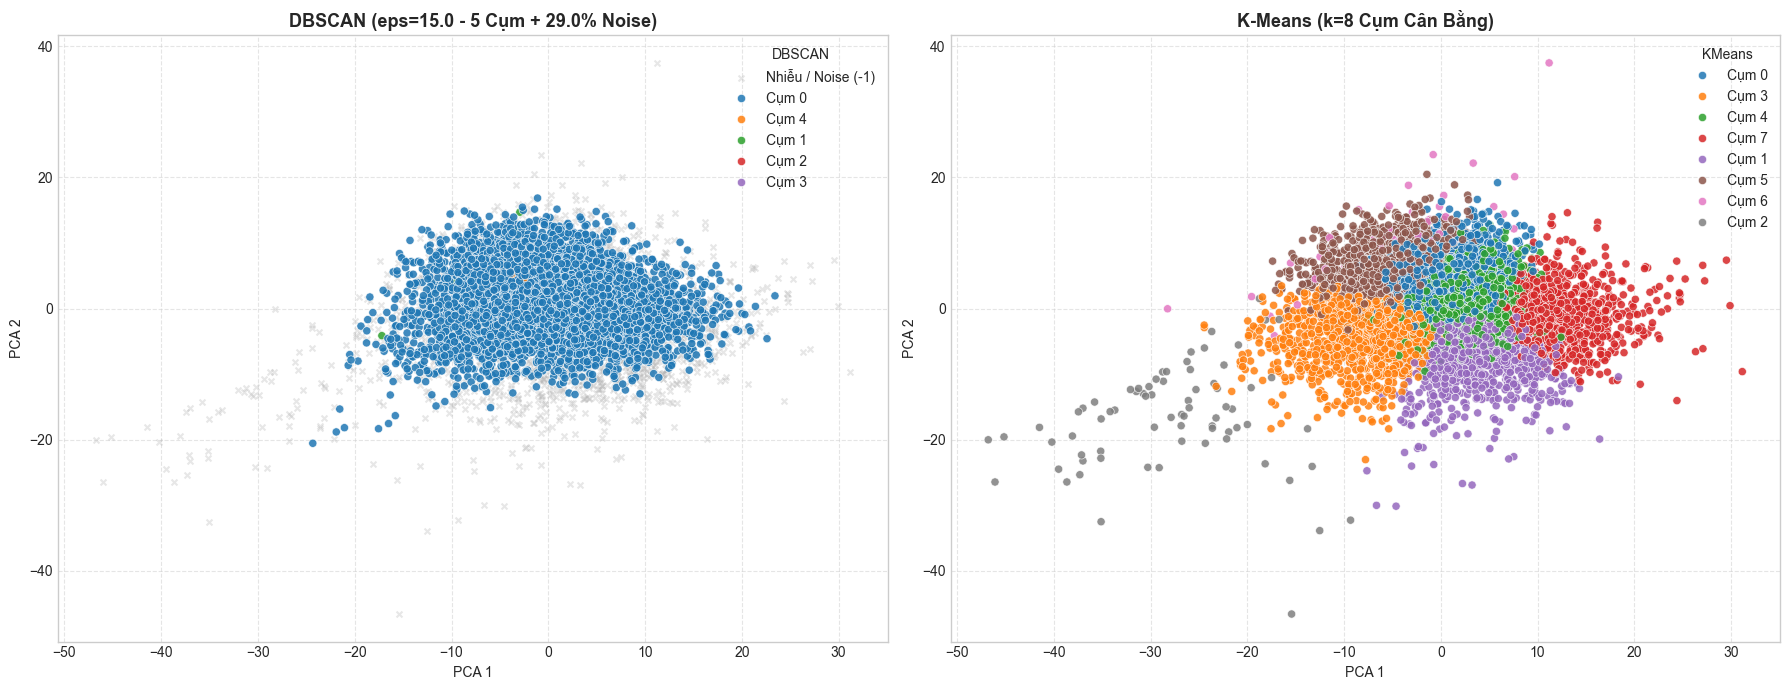

In [5]:
df_plot = pd.DataFrame({
    "PCA_1": X_pca[:, 0],
    "PCA_2": X_pca[:, 1],
    "DBSCAN": [f"Cụm {lbl}" if lbl != -1 else "Nhiễu / Noise (-1)" for lbl in dbscan_labels],
    "KMeans": [f"Cụm {lbl}" for lbl in kmeans_labels]
})

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. Biểu đồ DBSCAN
noise_pts = df_plot[df_plot["DBSCAN"] == "Nhiễu / Noise (-1)"]
if len(noise_pts) > 0:
    axes[0].scatter(noise_pts["PCA_1"], noise_pts["PCA_2"], c="#b0b0b0", alpha=0.3, s=18, marker="x", label="Nhiễu / Noise (-1)")
clustered_db = df_plot[df_plot["DBSCAN"] != "Nhiễu / Noise (-1)"]
sns.scatterplot(data=clustered_db, x="PCA_1", y="PCA_2", hue="DBSCAN", palette="tab10", s=35, alpha=0.85, ax=axes[0])
axes[0].set_title(f"DBSCAN (eps=15.0 - {db_n_clusters} Cụm + {db_noise_pct:.1f}% Noise)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Biểu đồ K-Means
sns.scatterplot(data=df_plot, x="PCA_1", y="PCA_2", hue="KMeans", palette="tab10", s=35, alpha=0.85, ax=axes[1])
axes[1].set_title("K-Means (k=8 Cụm Cân Bằng)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 6. Ma trận Đối sánh Thể loại Thực tế vs Cụm K-Means ($k=8$)

Phân bố thể loại trong từng cụm K-Means:


True Genre,Electronic,Experimental,Folk,Hip-Hop,Instrumental,International,Pop,Rock
K-Means Cluster,,,,,,,,
0,196,187,74,387,63,311,301,96
1,40,150,302,18,265,206,87,52
2,6,58,0,0,2,0,2,5
3,97,251,51,144,104,101,204,573
4,133,116,266,63,260,66,233,185
5,421,90,11,378,25,118,80,74
6,63,16,1,3,2,23,3,1
7,44,132,295,7,279,175,90,14


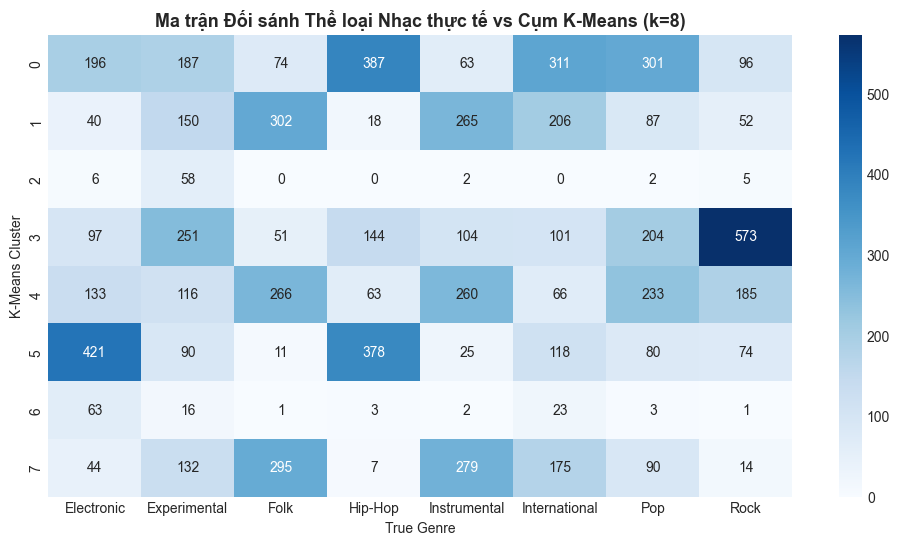

In [6]:
crosstab_km = pd.crosstab(
    kmeans_labels,
    y_genre,
    rownames=["K-Means Cluster"],
    colnames=["True Genre"]
)

plt.figure(figsize=(12, 6))
sns.heatmap(crosstab_km, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("Ma trận Đối sánh Thể loại Nhạc thực tế vs Cụm K-Means (k=8)", fontsize=13, fontweight="bold")
plt.show()

print("Phân bố thể loại trong từng cụm K-Means:")
crosstab_km

## 7. Kết luận Phân tích So sánh

1. **DBSCAN (Mật độ):** Phù hợp để phát hiện và gạt bỏ các bài hát thử nghiệm/dị biệt vào nhóm **Noise ($29.05\%$)**. Tuy nhiên, do đặc thù không gian âm thanh liên tục, DBSCAN bị dính chùm phần lớn dữ liệu vào một cụm chính, khó phân tách đều các thể loại.
2. **K-Means (Tâm cụm $k=8$):** Phân chia đều toàn bộ kho 8.000 bài hát thành **8 cụm rõ rệt**, đạt **Cluster Purity cao hơn ($27.83\%$)** và các chỉ số **ARI / NMI vượt trội**, thể hiện sự tương thích tốt hơn nhiều cho bài toán phân loại và gợi ý thể loại âm nhạc.